# Módulo 1 KDD (Etapas 1, 2 y 3): Definición del Objetivo, Selección de Datos, Limpieza y Diagnóstico de *Outliers*

**Autor:** Roberto Alejandro Chagra Martínez (`208447128`)  
**Proyecto Integrador:** Detección Automatizada de Fraude con Tarjetas de Crédito (`credit_card_fraud_detection_2026.csv`)

---
## 1. Definición del Objetivo y Selección de Datos (Prevención de *Data Leakage*)
En este primer módulo cargamos las `100,000` transacciones, cuantificamos el desbalance extremo de la variable objetivo (`is_fraud`) y auditamos qué columnas deben excluirse para evitar **fuga de información post-evento (*Data Leakage*)**.

MÓDULO 1 (ETAPAS 1-3 KDD): SELECCIÓN, LIMPIEZA Y DIAGNÓSTICO DE OUTLIERS
[Etapa 1-2] Dataset original cargado: 100,000 filas x 43 columnas
  - Transacciones Legítimas (0):    97,945 (97.945%)
  - Transacciones Fraudulentas (1): 2,055 (2.055%) | Ratio 1:47.7
  - Pérdida económica acumulada:    $279,842.20 USD


g:\Mi unidad\Drive.alumno.udg.mx\Proyectos\Deteccion_Automatizada_de_Fraude_Descubrimiento_de_Anomalías_y_Reglas_de_Decisión\modulos_kdd\fase1_seleccion_y_limpieza.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tipo_counts.values, y=tipo_counts.index, palette="OrRd_r", ax=axes[1], edgecolor="black")


[Etapa 2] Columnas descartadas por Data Leakage: ['fraud_type', 'fraud_amount_lost']
[Etapa 2] Dimensiones tras Selección: 100,000 filas x 35 columnas


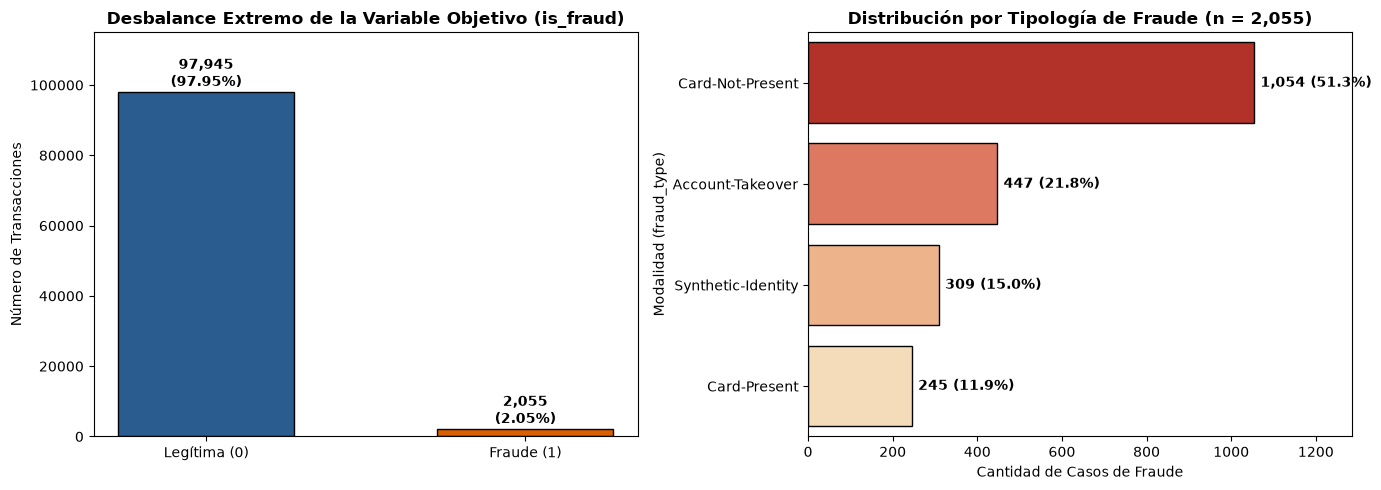

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

project_root = Path.cwd().parent if (Path.cwd().parent / 'Datasets').exists() else Path.cwd()
modulos_dir = next(d for d in project_root.iterdir() if d.is_dir() and 'Python' in d.name)
if str(modulos_dir) not in sys.path:
    sys.path.insert(0, str(modulos_dir))
from fase1_seleccion_y_limpieza import (
    cargar_y_seleccionar_datos,
    limpiar_y_diagnosticar_outliers,
)

csv_path = project_root / 'Datasets' / 'credit_card_fraud_detection_2026.csv'
out_dir = project_root / 'results'

df_raw, df_seleccionado = cargar_y_seleccionar_datos(csv_path, out_dir)
display(Image(filename=str(out_dir / '01_desbalance_y_tipologias.png')))

### Análisis de la Selección de Datos y Tipologías de Fraude
* **Desbalance extremo (`97.945%` vs. `2.055%`):** Solo **`2,055` transacciones son fraudulentas** frente a **`97,945` legítimas** (ratio `1 : 47.66`), con una pérdida acumulada de **\$279,842.20 USD**.
* **Exclusión de *Data Leakage*:** Se descartaron `fraud_type` y `fraud_amount_lost` por ser variables registradas después de confirmar el evento fraudulento, además de `6` columnas identificadoras, preservando **`35` columnas** limpias de fuga.

In [2]:
# Etapa 3 KDD: Limpieza estructural de 'browser' y diagnóstico de valores atípicos (1.5 x IQR)
df_limpio, df_iqr = limpiar_y_diagnosticar_outliers(df_seleccionado, out_dir)
display(df_iqr)


[Etapa 3] Nulos detectados en 'browser': 41,709 -> Origen por canal: {'In-store': 35777, 'ATM': 5932}


[Etapa 3] Nulos tras imputación estructural: 0 | Duplicados: 0

[Etapa 3] Diagnóstico de Valores Atípicos (1.5 x IQR):
                Variable    Q1  Mediana      Q3     IQR  Lim_Sup  Outliers_Count  Outliers_%  Tasa_Fraude_Normal_%  Tasa_Fraude_Outlier_%  Lift_Riesgo
      transaction_amount 21.28    52.26  129.72  108.44   292.38            9959        9.96                  1.95                   3.02         1.55
          amount_last_1h  0.00     0.00  100.01  100.01   250.03           11150       11.15                  1.85                   3.71         2.01
   distance_from_home_km 20.60  1949.95 8482.35 8461.75 21174.97               0        0.00                  2.05                   0.00         0.00
distance_from_last_tx_km  5.20    13.30   31.90   26.70    71.95           15617       15.62                  1.85                   3.18         1.72
     amount_vs_avg_ratio  0.21     0.58    1.66    1.45     3.84           11309       11.31                  1.88            

,Variable,Q1,Mediana,Q3,IQR,Lim_Sup,Outliers_Count,Outliers_%,Tasa_Fraude_Normal_%,Tasa_Fraude_Outlier_%,Lift_Riesgo
0,transaction_amount,21.28,52.26,129.72,108.44,292.38,9959,9.96,1.95,3.02,1.55
1,amount_last_1h,0.00,0.00,100.01,100.01,250.03,11150,11.15,1.85,3.71,2.01
2,distance_from_home_km,20.60,1949.95,8482.35,8461.75,21174.97,0,0.00,2.05,0.00,0.00
3,distance_from_last_tx_km,5.20,13.30,31.90,26.70,71.95,15617,15.62,1.85,3.18,1.72
4,amount_vs_avg_ratio,0.21,0.58,1.66,1.45,3.84,11309,11.31,1.88,3.44,1.83
5,transactions_last_1h,0.00,0.00,1.00,1.00,2.50,8990,8.99,1.71,5.57,3.26


### Análisis de la Limpieza Estructural y de los Valores Atípicos (*Outliers*)
* **Prevención del Sesgo de Selección:** Los `41,709` valores faltantes en `browser` corresponden al $100\%$ de las operaciones físicas en tienda (`35,777` `In-store`) y cajeros (`5,932` `ATM`). Imputarlos con `'No_Aplica_Fisico'` preserva el $100\%$ de la muestra sin sesgar el modelo hacia canales digitales.
* **Outlier $\neq$ Error:** Los valores atípicos en `transactions_last_1h` ($> 2.5$) exhiben una tasa de fraude del **`5.57%`** (**`3.26x` más riesgo** que el rango normal de `1.71%`), por lo que se conservan íntegramente.

### Q&A
* **¿Por qué se excluyen `fraud_type` y `fraud_amount_lost` en la Etapa 2?** Porque ambas variables solo existen una vez que el fraude ha ocurrido y se ha contabilizado; mantenerlas introduciría *Data Leakage* artificial.

### Data Analysis Key Findings
* El dataset cuenta con `100,000` transacciones y una prevalencia de fraude del `2.055%` (`2,055` casos), donde la modalidad *Card-Not-Present* representa el `51.3%` (`1,054` casos).
* La imputación estructural de `browser` como `'No_Aplica_Fisico'` resuelve los `41,709` valores faltantes sin perder un solo registro presencial.
* Las instancias atípicas identificadas por el criterio $1.5 \times \text{IQR}$ en velocidad y monto triplican la probabilidad base de fraude (`Lift = 3.26x`).

### Insights or Next Steps
* Pasar el conjunto limpio de `100,000` filas $\times$ `35` columnas al **Módulo 2 (`fase2_transformacion_y_seleccion.py`)** para construir variables derivadas de señales débiles y aplicar escalamiento robusto sin fuga de datos.